<a href="https://colab.research.google.com/github/tajeshwar74/scikit-learn/blob/main/Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import random
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = []

for _ in range(500):
    team_name = f"Team {chr(random.randint(65, 90))}"
    season = random.randint(2010, 2022)
    wins = random.randint(50, 110)
    losses = 162 - wins
    hits = random.randint(1200, 1600)
    doubles = random.randint(200, 350)
    triples = random.randint(10, 40)
    home_runs = random.randint(100, 250)
    strikeouts = random.randint(1000, 1500)

    # Apply adjustments to create correlations
    hits_adjusted = hits + (wins - 80) * 5
    doubles_adjusted = doubles + (wins - 80) * 2
    triples_adjusted = triples + (wins - 80)
    home_runs_adjusted = home_runs + (wins - 80) * 3
    strikeouts_adjusted = strikeouts - (wins - 80) * 10

    data.append([team_name, season, wins, losses, hits_adjusted, doubles_adjusted, triples_adjusted, home_runs_adjusted, strikeouts_adjusted])

# Define column names
columns = ["Team", "Season", "Wins", "Losses", "Hits", "Doubles", "Triples", "HomeRuns", "Strikeouts"]

# Create a Pandas DataFrame
df = pd.DataFrame(data, columns=columns)
df.head()

,Team,Season,Wins,Losses,Hits,Doubles,Triples,HomeRuns,Strikeouts
0,Team Q,2011,91,71,1428,282,35,202,1274
1,Team F,2015,83,79,1276,208,15,155,1455
2,Team O,2010,55,107,1287,154,6,109,1466
3,Team J,2014,95,67,1301,373,28,269,1162
4,Team N,2021,69,93,1464,320,27,179,1458


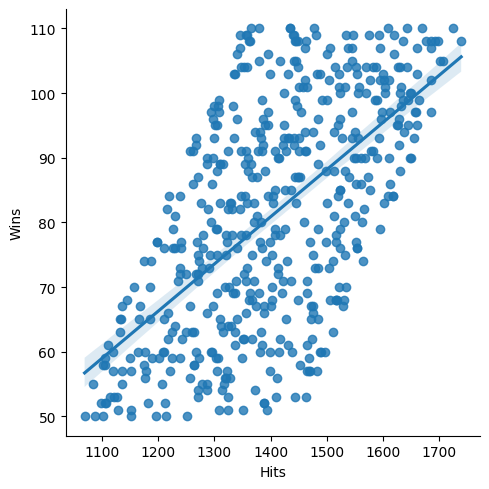

In [5]:
sns.lmplot(x="Hits", y="Wins", data=df)
plt.show()

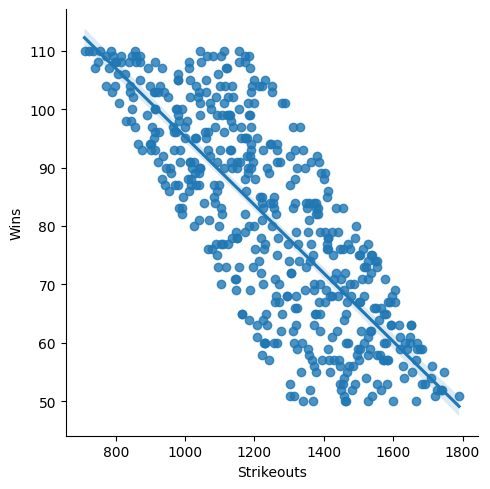

In [6]:
sns.lmplot(x="Strikeouts", y="Wins", data=df)
plt.show()

In [7]:
df2 = df.drop(columns=['Team', 'Season', 'Losses'])

In [8]:
df2.head()

,Wins,Hits,Doubles,Triples,HomeRuns,Strikeouts
0,91,1428,282,35,202,1274
1,83,1276,208,15,155,1455
2,55,1287,154,6,109,1466
3,95,1301,373,28,269,1162
4,69,1464,320,27,179,1458


In [9]:
X = df[['Hits', 'Doubles', 'Triples', 'HomeRuns', 'Strikeouts']]

In [10]:
y = df['Wins']

In [11]:
X_train, X_test, y_train, y_split = train_test_split(X, y, test_size=0.2, random_state=13)

In [12]:
lr = LinearRegression()

In [13]:
lr.fit(X_train, y_train)

LinearRegression()

In [14]:
lr.score(X_train, y_train)

0.8924845106067617

In [16]:
lr.score(X_test, y_split)

0.9020428478590554

In [17]:
y_pred = lr.predict(X_test)

In [19]:
mean_absolute_error(y_split, y_pred)

4.4937639957960505

In [20]:
mean_squared_error(y_split, y_pred)

29.664364382842244

In [21]:
r2_score(y_split, y_pred)

0.9020428478590554

In [22]:
lr.coef_

array([ 0.01429482,  0.03553522,  0.44955284,  0.04195859, -0.01531318])

In [23]:
lr.intercept_

np.float64(51.10772592863577)